In [34]:
import numpy as np
import pandas as pd

def_data = pd.read_csv("./23-24/inputs/fg_data_def.csv")
def_data.columns.tolist()

['Unnamed: 0',
 'fpl_id',
 'round',
 'position',
 'xP',
 'was_home',
 'team',
 'opponent_team',
 'elo',
 'elo_h',
 'elo_a',
 'opp_elo',
 'opp_elo_h',
 'opp_elo_a',
 'team_h_difficulty',
 'team_a_difficulty',
 'win_prob',
 'value',
 'selected_by_percent',
 'transfers_in',
 'transfers_out',
 'xP_rolling_3',
 'xGChain_rolling_3',
 'xGBuildup_rolling_3',
 'expected_goals_rolling_3',
 'expected_assists_rolling_3',
 'expected_goal_involvements_rolling_3',
 'minutes_rolling_3',
 'starts_rolling_3',
 'expected_goals_conceded_rolling_3',
 'clean_sheets_rolling_3',
 'saves_rolling_3',
 'ict_index_rolling_3',
 'influence_rolling_3',
 'creativity_rolling_3',
 'threat_rolling_3']

In [ ]:
num_cols_def = [
    # "xP",
    # "elo",
    "elo_h",
    "elo_a",
    # "opp_elo",
    # "opp_elo_h",
    # "opp_elo_a",
    # "team_h_difficulty",
    # "team_a_difficulty",
    "win_prob",
    "value",
    "selected_by_percent",
    "transfers_in",
    "transfers_out",
    "xP_rolling_3",
    "xGChain_rolling_3",
    "xGBuildup_rolling_3",
    "expected_goals_rolling_3",
    "expected_assists_rolling_3",
    "expected_goal_involvements_rolling_3",
    "minutes_rolling_3",
    "starts_rolling_3",
    "expected_goals_conceded_rolling_3",
    "clean_sheets_rolling_3",
    # "saves_rolling_3",
    "ict_index_rolling_3",
    "influence_rolling_3",
    "creativity_rolling_3",
    "threat_rolling_3",
]  # numeric features


In [ ]:
h = def_data[num_cols_def]
h = h[h["minutes_rolling_3"] > 15]
h

,xP,elo_h,elo_a,win_prob,value,selected_by_percent,transfers_in,transfers_out,xP_rolling_3,xGChain_rolling_3,...,expected_assists_rolling_3,expected_goal_involvements_rolling_3,minutes_rolling_3,starts_rolling_3,expected_goals_conceded_rolling_3,clean_sheets_rolling_3,ict_index_rolling_3,influence_rolling_3,creativity_rolling_3,threat_rolling_3
6,2.5,1369.91,1677.28,0.632,48,13.7,32915,161644,0.833333,0.204987,...,0.003333,0.003333,36.666667,0.333333,0.563333,0.000000,1.200000,11.400000,0.733333,0.000000
7,2.5,1681.25,1583.69,0.565,48,13.0,21035,83534,1.166667,0.233785,...,0.010000,0.010000,60.000000,0.666667,0.420000,0.333333,1.566667,13.600000,2.133333,0.000000
8,4.5,1334.90,1676.89,0.618,47,12.8,54236,75957,2.000000,0.233785,...,0.013333,0.036667,90.000000,1.000000,0.920000,0.333333,2.166667,16.200000,2.700000,2.666667
9,4.5,1683.21,1809.81,0.324,47,12.2,80932,129943,3.166667,0.033903,...,0.010000,0.033333,90.000000,1.000000,0.830000,0.666667,2.233333,17.400000,2.066667,2.666667
10,5.5,1489.09,1694.97,0.423,47,12.9,106197,44609,3.833333,0.053239,...,0.003333,0.026667,90.000000,1.000000,0.913333,0.666667,1.866667,14.600000,1.100000,2.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3716,-0.3,1323.90,1376.26,0.316,40,0.0,306,241,0.533333,0.153752,...,0.003333,0.023333,75.000000,1.000000,2.273333,0.000000,1.500000,12.000000,1.400000,1.333333
3719,0.0,1437.88,1495.30,0.328,40,0.0,1046,358,-0.266667,0.020080,...,0.070000,0.083333,30.000000,0.333333,0.433333,0.000000,1.100000,2.933333,6.266667,1.666667
3720,-0.3,1478.18,1596.52,0.350,40,0.0,1223,254,-0.266667,0.098320,...,0.090000,0.110000,60.000000,0.666667,1.186667,0.000000,2.000000,4.600000,12.200000,3.000000
3721,0.7,1483.54,1540.04,0.439,40,0.0,765,373,-0.100000,0.078240,...,0.020000,0.026667,30.333333,0.333333,0.753333,0.000000,1.066667,1.733333,6.033333,2.666667


In [ ]:
preds = pd.read_csv("./23-24/models/predictions.csv")
def_preds = preds[preds["pos"] == "DEF"]

gw_preds = def_preds[def_preds["round"] == 20]
gw_preds = gw_preds[gw_preds["minutes"] > 0]
gw_preds

,pos,round,fpl_id,value,name,team,total_points,selected_at,model,pred,xP,in_selection,minutes,played
6554,DEF,20,5,50,Gabriel dos Santos Magalhães,Arsenal,1,15,ens_top3,5.092187,4.0,False,90.0,True
6556,DEF,20,10,43,Jakub Kiwior,Arsenal,1,15,ens_top3,1.505548,1.0,False,45.0,True
6557,DEF,20,20,56,William Saliba,Arsenal,0,15,ens_top3,4.227109,2.7,False,90.0,True
6560,DEF,20,25,45,Takehiro Tomiyasu,Arsenal,1,15,ens_top3,1.465556,0.0,False,45.0,True
6561,DEF,20,27,39,Auston Trusty,Sheffield Utd,1,15,ens_top3,0.448643,0.3,False,90.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6776,DEF,20,693,40,Luke Thomas,Sheffield Utd,1,15,ens_top3,-0.426644,-1.3,False,89.0,True
6777,DEF,20,696,45,Murillo Santiago Costa dos Santos,Nott'm Forest,2,15,ens_top3,1.638703,1.2,False,90.0,True
6779,DEF,20,699,45,Clément Lenglet,Aston Villa,2,15,ens_top3,3.008542,1.8,False,61.0,True
6781,DEF,20,703,40,Jonny Evans,Man Utd,1,15,ens_top3,3.771918,2.2,False,90.0,True


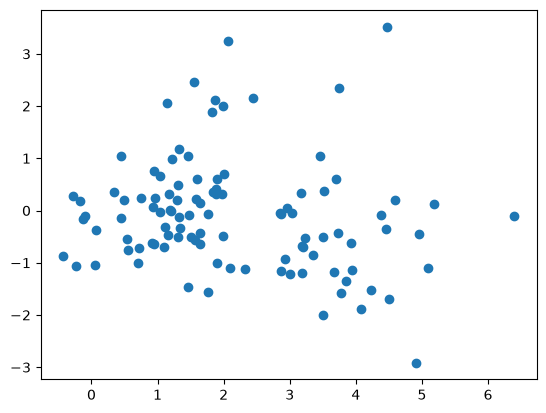

In [ ]:
import scipy
import matplotlib.pyplot as plt

xP, xP_pred = gw_preds["xP"], gw_preds["pred"]
resid = xP - xP_pred
# resid.hist(bins=50); scipy.stats.probplot(resid, plot=plt)
plt.scatter(xP_pred, resid)  # does the spread grow as predictions grow?


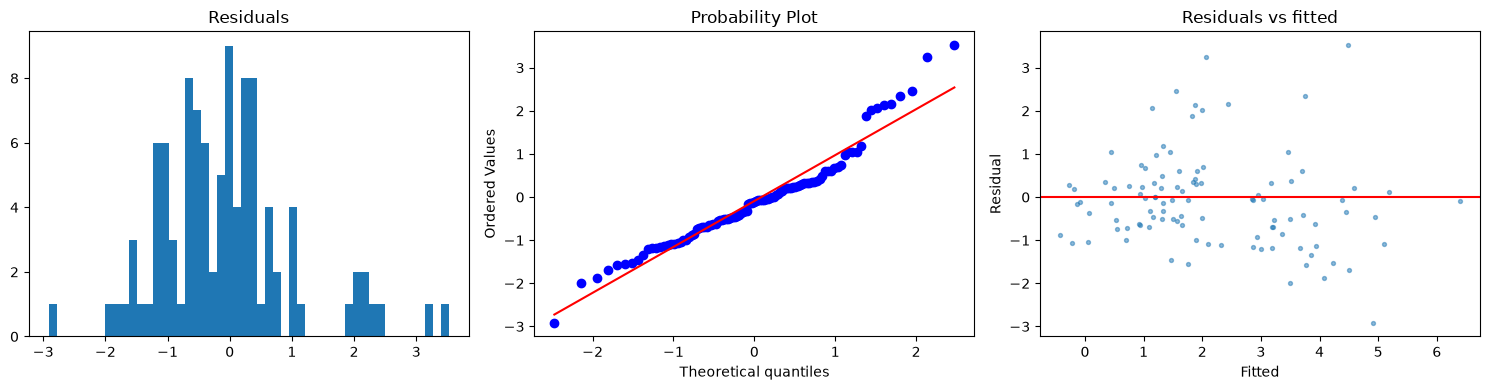

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(resid, bins=50)
ax[0].set_title("Residuals")
scipy.stats.probplot(resid, plot=ax[1])
ax[2].scatter(xP_pred, resid, s=8, alpha=0.5)
ax[2].axhline(0, c="r")
ax[2].set(xlabel="Fitted", ylabel="Residual", title="Residuals vs fitted")
plt.tight_layout()
